# Validate against buoy observations

Compare **offshore hindcast** (closest goal node), **bulk metamodel**, **spectral metamodel**, and **dynamic SnapWave** to buoy records.

**Prerequisites**

1. Fitted models — `06_Validate_Metamodel.ipynb` (`mm.fit_all`)
2. Dynamic run for the same period — `08_Dynamic_Cases_Generation.ipynb`
3. Observations GeoJSON — `03_Generate_Observations_Configuration.ipynb` → `inputs/Observations/<Case>_observations.json`
4. Processed buoy file(s) under `inputs/Observations/processed/` (you build these in the notebook below)

Use the **same `period`** for buoy data, reconstruction, and dynamic output.

Comparisons request **`hs`, `tp`, `dir`, and `spr`**. Variables missing from the buoy
file or any model are skipped automatically.

In [1]:
import matplotlib.pyplot as plt
import xarray as xr
from utils.config import SIMULATIONS, resolve
from utils.evaluation import validation as val
from utils.model import metamodel as mm
from utils.observation import onshore_sites as obs

## Configuration

Pick buoy sites from the observations GeoJSON (`instrument_id` keys). SnapWave site
labels are `buoy_{instrument_id}`. Point each site to its processed NetCDF (bulk or
spectral) under `inputs/Observations/processed/`.

In [2]:
period = "2010"
offshore_name = "WHACS"
mda_n = 450  # must match a fitted mda_candidates entry
pca_variance = 0.99

# instrument_id values from your observations GeoJSON (notebook 03)
buoy_instruments = ["buoy_Sydney_Buoy"]  # instrument_id values from notebook 03
sites = [obs.snapwave_site_id(iid) for iid in buoy_instruments]

# Processed observation NetCDF per SnapWave site id
buoy_raw_files = {
    obs.snapwave_site_id("buoy_Sydney_Buoy"): (
        "inputs/Observations/processed/Sydney_Buoy.nc"
    ),
}

requested_variables = ["hs", "tp", "dir", "spr"]

dynamic_path = (
    resolve(SIMULATIONS["dynamic_cases"]) / f"Dynamic_Cases_{offshore_name}_{period}.nc"
)

print("Observations JSON:", obs.geojson_path())
print(f"period         : {period}")
print(f"mda_n          : {mda_n}")
print(f"sites          : {sites}")
print(f"requested vars : {requested_variables}")
print(f"dynamic path   : {dynamic_path}")
print(f"dynamic exists : {dynamic_path.is_file()}")

Observations JSON: /home/tausiaj/GitHub-GeoOcean/HyGloW/NewSouthWales/inputs/Observations/NewSouthWales_observations.json
period         : 2010
mda_n          : 450
sites          : ['buoy_Sydney_Buoy']
requested vars : ['hs', 'tp', 'dir', 'spr']
dynamic path   : /hyglowdata/NewSouthWales/SnapWave_CASES_Dynamic/Dynamic_Cases_WHACS_2010.nc
dynamic exists : True


## 1 · Check models

In [3]:
mm.require_models_all(mda_n, pca_variance=pca_variance)

## 2 · Process buoy observations

Load each processed file, rename variables to HyGloW names (`hs`, `tp`, `dir`, `spr`),
slice to `period`, and build a validation dataset on `(time, sites)` with CF-style
attributes. Site metadata (lon/lat/depth) comes from the observations GeoJSON.

In [4]:
# CF-style attributes for validation plots
_BUOY_VAR_ATTRS = {
    "hs": {"standard_name": "sea_surface_wave_significant_height", "units": "m"},
    "tp": {"standard_name": "sea_surface_wave_period", "units": "s"},
    "dir": {"standard_name": "sea_surface_wave_from_direction", "units": "degree"},
    "spr": {
        "standard_name": "sea_surface_wave_directional_spread",
        "units": "degree",
    },
}

chunks: list[xr.Dataset] = []
for site_id in sites:
    raw = xr.open_dataset(resolve(buoy_raw_files[site_id])).sel(time=period)

    if "Efth" in raw or "efth" in raw:
        spec_name = "Efth" if "Efth" in raw else "efth"
        stats = raw[spec_name].spec.stats(["hs", "tp", "dm", "dspr"]).load()
        site_ds = stats.rename({"dm": "dir", "dspr": "spr"})
    else:
        rename = {}
        if "dspr" in raw.data_vars and "spr" not in raw.data_vars:
            rename["dspr"] = "spr"
        if rename:
            raw = raw.rename(rename)
        vars_out = {}
        for name in requested_variables:
            if name in raw.data_vars:
                vars_out[name] = raw[name]
            elif name == "dir" and "dm" in raw.data_vars:
                vars_out["dir"] = raw["dm"]
        if "hs" not in vars_out:
            raise ValueError(f"{site_id}: processed buoy file must contain hs or Efth")
        site_ds = xr.Dataset(vars_out)

    site_ds = site_ds.expand_dims(sites=[site_id]).transpose("time", "sites")
    for var, attrs in _BUOY_VAR_ATTRS.items():
        if var in site_ds:
            site_ds[var].attrs.update(attrs)
    chunks.append(obs.attach_buoy_site_meta(site_ds, site_id))

buoy = xr.concat(chunks, dim="sites") if len(chunks) > 1 else chunks[0]
buoy

<xarray.Dataset> Size: 261kB
Dimensions:         (sites: 1, time: 8140)
Coordinates:
  * sites           (sites) object 8B 'buoy_Sydney_Buoy'
    site_source     (sites) <U4 16B 'buoy'
    site_label      (sites) <U11 44B 'Sydney_Buoy'
    site_longitude  (sites) float64 8B 151.4
    site_latitude   (sites) float64 8B -33.77
    site_depth      (sites) float64 8B -85.0
  * time            (time) datetime64[ns] 65kB 2010-01-01 ... 2010-12-31T23:0...
Data variables:
    hs              (time, sites) float64 65kB 0.923 0.868 0.866 ... 0.947 0.926
    tp              (time, sites) float64 65kB 6.16 7.03 6.16 ... 4.94 8.52 4.94
    dir             (time, sites) float64 65kB 75.0 68.0 73.0 ... 51.0 89.0 58.0

## 3 · Reconstruct metamodel, load dynamic, and closest-goal offshore hindcast

Metamodel bulk/spectral reconstructions, dynamic SnapWave, and bulk offshore forcing
at each buoy's **closest goal hindcast node** (all sources in the case JSON —
currently WHACS only).

In [5]:
bulk = mm.reconstruct(
    period,
    mda_n,
    spectral=False,
    offshore_name=offshore_name,
    sites=sites,
    pca_variance=pca_variance,
)

spectral = mm.reconstruct(
    period,
    mda_n,
    spectral=True,
    offshore_name=offshore_name,
    sites=sites,
    pca_variance=pca_variance,
)

if not dynamic_path.is_file():
    raise FileNotFoundError(
        f"Dynamic output not found: {dynamic_path}\n"
        "Run 08_Dynamic_Cases_Generation for this period or change `period`."
    )

dynamic = xr.open_dataset(dynamic_path).sel(time=period)
site_ids = mm.resolve_reconstruction_sites(dynamic, sites)
dynamic = dynamic.sel(sites=site_ids).load()

offshore_hindcast, closest_goals = val.load_offshore_hindcast_at_buoys(
    period,
    sites,
    variables=requested_variables,
)
closest_goals

estimates = {
    **offshore_hindcast,
    "Bulk metamodel": bulk,
    "Spectral metamodel": spectral,
    "Dynamic SnapWave": dynamic,
}

variables = val.resolve_comparison_variables(
    buoy,
    *estimates.values(),
    variables=requested_variables,
)
print(f"Comparing: {variables}")

Comparing: ['hs', 'tp', 'dir']


## 4 · Metrics vs buoy

In [6]:
results = val.compare_all(
    buoy,
    estimates,
    sites=sites,
    variables=variables,
    reference_label="Buoy",
    pca_variance=pca_variance,
)

summary = val.metrics_summary(results)
summary

,pca_variances,group,site_source,site_label,variable,label,n,bias,rmse,r2,estimate_label,reference_label,model
0,"{'hs': 0.99, 'dir': 0.99, 'spr': 0.99}",buoy_Sydney_Buoy,buoy,waves,hs,Hs,2732,0.310257,0.475714,0.551631,WHACS (closest goal),Buoy,WHACS (closest goal)
1,"{'hs': 0.99, 'dir': 0.99, 'spr': 0.99}",buoy_Sydney_Buoy,buoy,waves,tp,Tp,2732,-0.460556,2.339357,-0.036930,WHACS (closest goal),Buoy,WHACS (closest goal)
2,"{'hs': 0.99, 'dir': 0.99, 'spr': 0.99}",buoy_Sydney_Buoy,buoy,waves,dir,Dir,2732,-0.910871,35.460062,0.280564,WHACS (closest goal),Buoy,WHACS (closest goal)
3,"{'hs': 0.99, 'dir': 0.99, 'spr': 0.99}",buoy_Sydney_Buoy,buoy,waves,hs,Hs,2732,0.076298,0.355902,0.689534,Bulk metamodel,Buoy,Bulk metamodel
4,"{'hs': 0.99, 'dir': 0.99, 'spr': 0.99}",buoy_Sydney_Buoy,buoy,waves,tp,Tp,2732,-0.505970,2.330603,-0.113322,Bulk metamodel,Buoy,Bulk metamodel
5,"{'hs': 0.99, 'dir': 0.99, 'spr': 0.99}",buoy_Sydney_Buoy,buoy,waves,dir,Dir,2732,-2.970964,28.822554,0.524689,Bulk metamodel,Buoy,Bulk metamodel
6,"{'hs': 0.99, 'dir': 0.99, 'spr': 0.99}",buoy_Sydney_Buoy,buoy,waves,hs,Hs,2730,0.074915,0.353631,0.680239,Spectral metamodel,Buoy,Spectral metamodel
7,"{'hs': 0.99, 'dir': 0.99, 'spr': 0.99}",buoy_Sydney_Buoy,buoy,waves,tp,Tp,2730,-0.782593,2.416938,-0.239818,Spectral metamodel,Buoy,Spectral metamodel
8,"{'hs': 0.99, 'dir': 0.99, 'spr': 0.99}",buoy_Sydney_Buoy,buoy,waves,dir,Dir,2732,0.874942,28.246191,0.543508,Spectral metamodel,Buoy,Spectral metamodel
9,"{'hs': 0.99, 'dir': 0.99, 'spr': 0.99}",buoy_Sydney_Buoy,buoy,waves,hs,Hs,2732,0.099908,0.341105,0.666577,Dynamic SnapWave,Buoy,Dynamic SnapWave


## 5 · Scatter plots

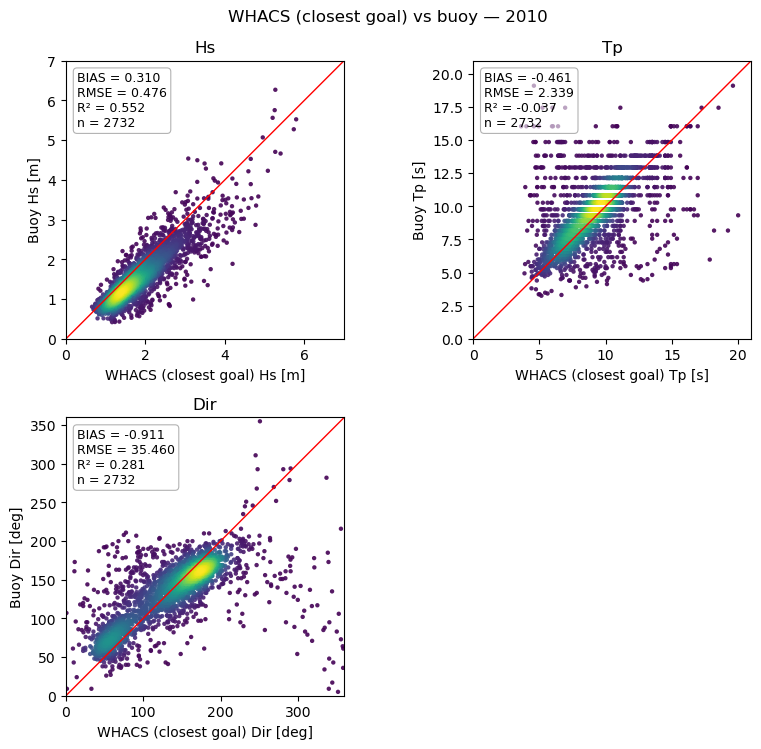

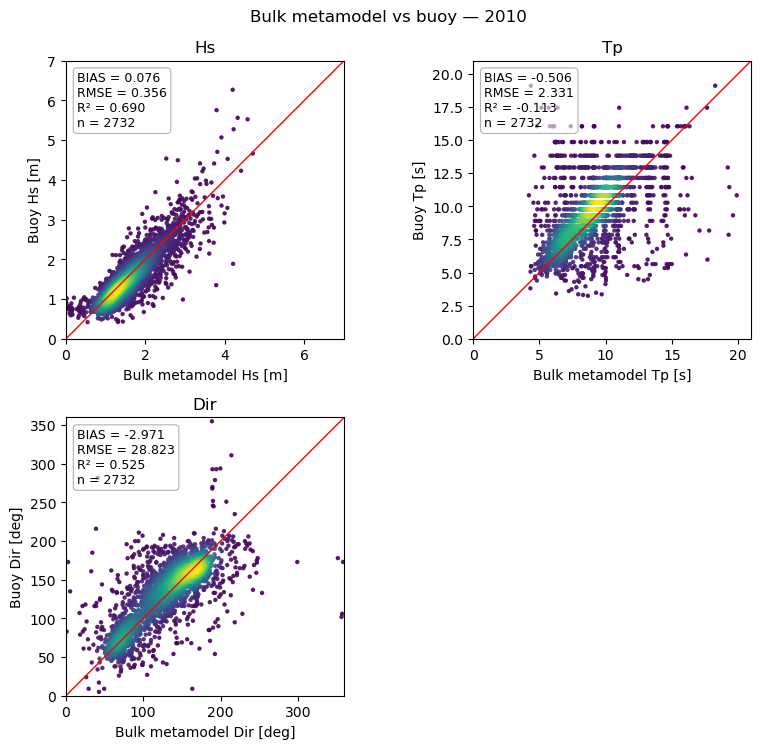

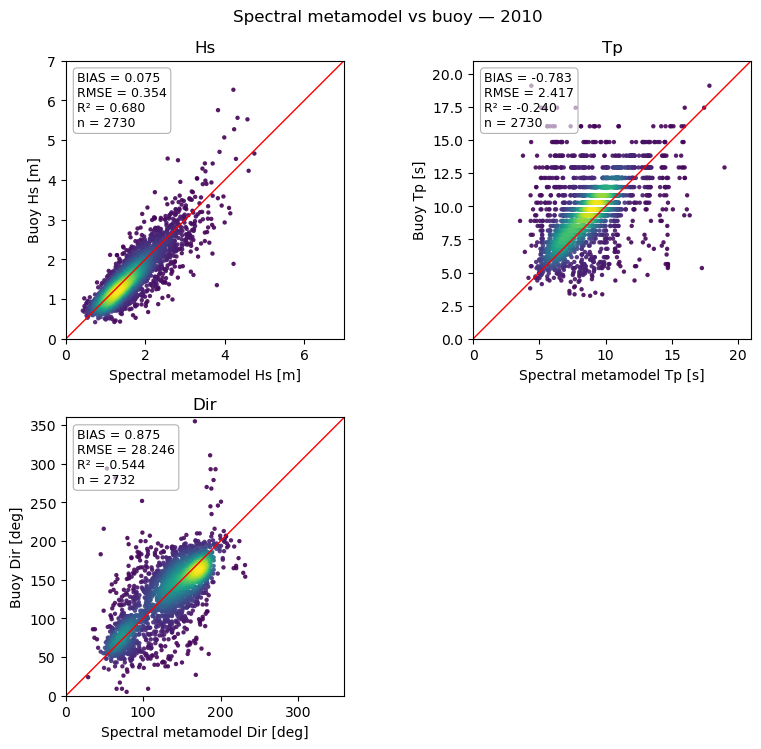

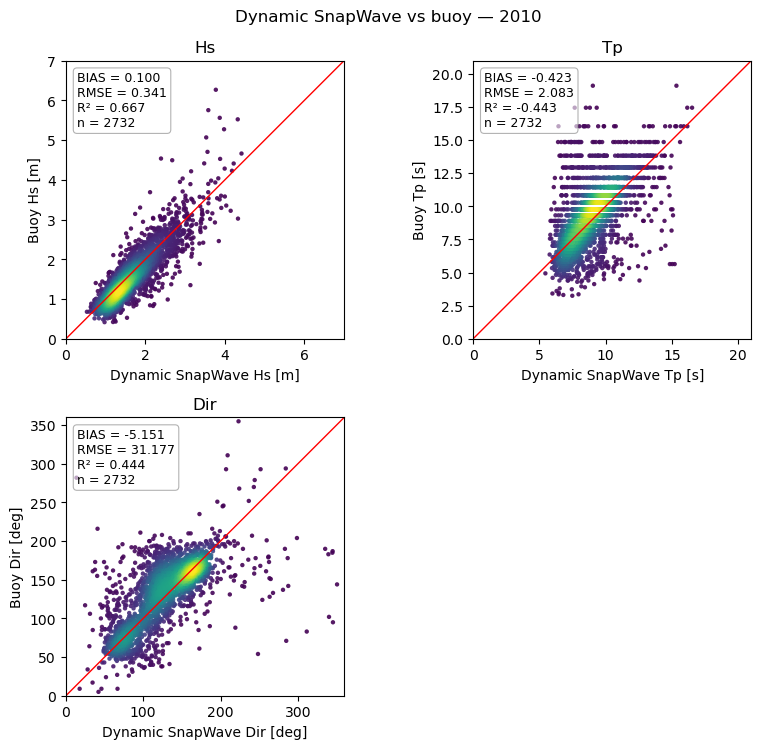

In [7]:
group = mm.resolve_sites(estimates["Spectral metamodel"], sites)[0]

for name, result in results.items():
    result.plot_scatter(
        group,
        variables=variables,
        estimate_label=name,
        reference_label="Buoy",
    )
    plt.suptitle(f"{name} vs buoy — {period}")
    plt.show()

## 6 · Time series

Line plots of buoy observations vs each model over the validation period (direction as scatter).

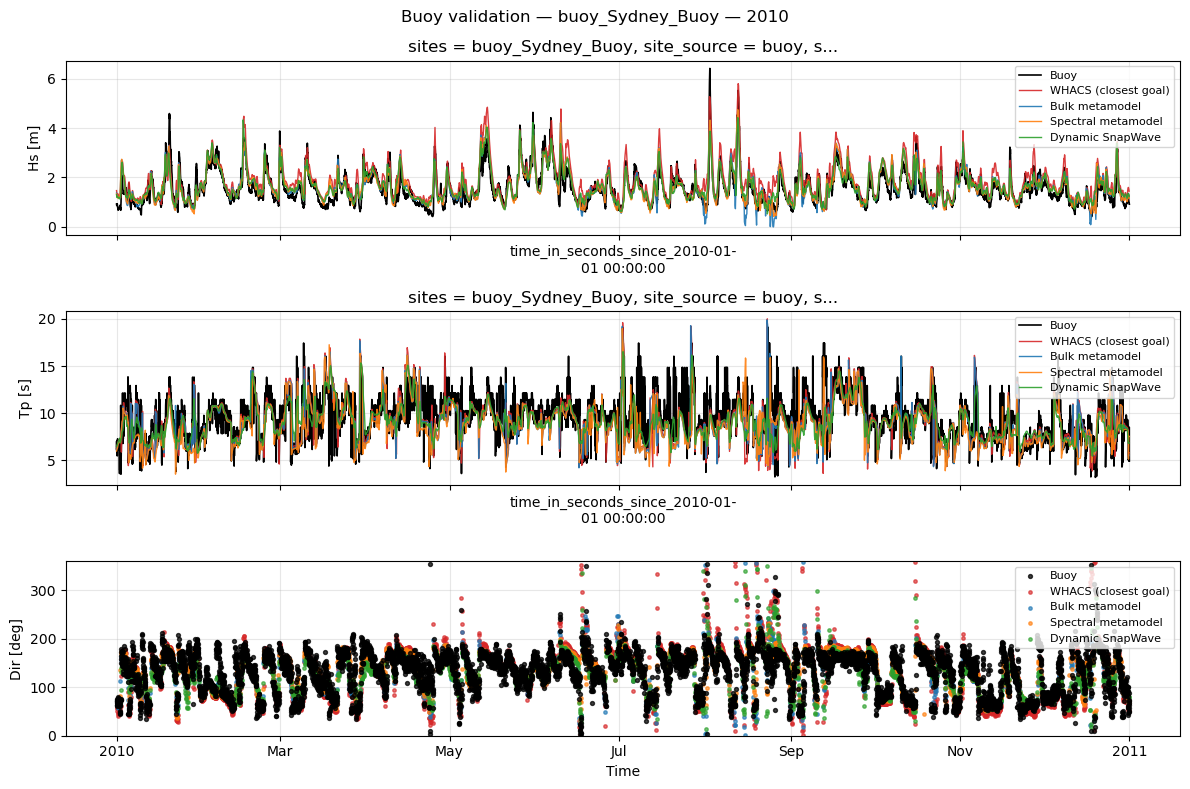

In [8]:
for site in sites:
    val.plot_buoy_timeseries(buoy, estimates, site, variables=variables)
    plt.suptitle(f"Buoy validation — {site} — {period}")
    plt.show()